# Fracture networks as graphs

## Transforming the fracture graph to 3d fracture planes for a fracture network using dips

### Import packages

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pickle

from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

## Creating a graph from the fracture network 

In [2]:
# Read the graphs
G = pickle.load(open(f'data/graphs/tsan_fracgraph.pickle', 'rb'))

In [3]:
print(G.nodes(data=True))

[(0, {'pos': (2583484.98599, 1128945.3281), 'length': [82.092], 'azimuth': [144.47], 'rad': [2.52], 'family': ['NS'], 'mdip': [76], 'kine': ['s'], 'aperture': [10], 'target': 0, 'betweenness_centrality': 0.0, 'betweenness_length': 0.0, 'percolation_centrality': 0.0, 'percolation_length': 0.0}), (1, {'pos': (2583532.69424, 1128878.52193), 'length': [82.092, 41.202], 'azimuth': [144.47, 137.6], 'rad': [2.52, 2.4], 'family': ['NS', 'NWSE'], 'mdip': [76, 81], 'kine': ['s', 's'], 'aperture': [10, 30], 'target': 0, 'betweenness_centrality': 0.001, 'betweenness_length': 0.001, 'percolation_centrality': 0.0, 'percolation_length': 0.0}), (2, {'pos': (2583560.47492, 1128848.09372), 'length': [41.202, 49.746], 'azimuth': [137.6, 140.46], 'rad': [2.4, 2.45], 'family': ['NWSE', 'NS'], 'mdip': [81, 76], 'kine': ['s', 's'], 'aperture': [30, 10], 'target': 0, 'betweenness_centrality': 0.001, 'betweenness_length': 0.001, 'percolation_centrality': 0.0, 'percolation_length': 0.0}), (3, {'pos': (2583592.1

In [4]:
pos_2d = nx.get_node_attributes(G, 'pos')

## Extend 2D graph --> 3D representation

In [5]:
print(G.edges(data=True))

[(0, 1, {'length': 82.092, 'rad': 2.52, 'azimuth': 144.47, 'family': 'NS', 'mdip': 76, 'kine': 's', 'aperture': 10}), (1, 2, {'length': 41.202, 'rad': 2.4, 'azimuth': 137.6, 'family': 'NWSE', 'mdip': 81, 'kine': 's', 'aperture': 30}), (2, 3, {'length': 49.746, 'rad': 2.45, 'azimuth': 140.46, 'family': 'NS', 'mdip': 76, 'kine': 's', 'aperture': 10}), (3, 4, {'length': 10.189, 'rad': 2.19, 'azimuth': 125.5, 'family': 'NWSE', 'mdip': 81, 'kine': 's', 'aperture': 30}), (3, 21, {'length': 59.623, 'rad': -1.88, 'azimuth': 252.57, 'family': 'EW', 'mdip': 75, 'kine': 'd', 'aperture': 20}), (3, 22, {'length': 61.715, 'rad': 1.27, 'azimuth': 72.54, 'family': 'EW', 'mdip': 75, 'kine': 'd', 'aperture': 20}), (5, 6, {'length': 24.141, 'rad': 1.41, 'azimuth': 80.54, 'family': 'EW', 'mdip': 75, 'kine': 'd', 'aperture': 20}), (6, 7, {'length': 44.593, 'rad': 1.21, 'azimuth': 69.15, 'family': 'EW', 'mdip': 75, 'kine': 'd', 'aperture': 20}), (7, 8, {'length': 17.969, 'rad': 1.68, 'azimuth': 96.34, 'fami

In [6]:
# Extrude 2D edges into vertical planes with dip
def extrude(graph, pos_2d, length=5):
    plane_faces = []

    for u, v in graph.edges():
        x1, y1 = pos_2d[u]
        x2, y2 = pos_2d[v]

        # mid point of the trace
        mx = (x1 + x2) / 2
        my = (y1 + y2) / 2
        mz = 0

        # dip angle
        dip_deg = graph.edges[u,v]['mdip']
        dip_rad = np.radians(dip_deg)

        strike_deg = graph.edges[u,v]['azimuth']
        strike_rad = np.radians(strike_deg)

        dip_dir = strike_rad + np.pi/2

        # extensions
        dx = length * np.sin(dip_rad) * np.sin(dip_dir)
        dy = length * np.sin(dip_rad) * np.cos(dip_dir)
        dz = length * np.cos(dip_rad)

        # trace direction and shift
        #vec = np.array([x2 - x1, y2 - y1])
        #vec_len = np.linalg.norm(vec)
        #if vec_len == 0:
            #continue
        #unit_vec = vec / vec_len
        #dx, dy = unit_vec * dh

        # define 3d points
        p1 = [x1, y1, 0]
        p2 = [x2, y2, 0]
        p3 = [x2 + dx, y2 + dy, dz]
        p4 = [x1 + dx, y1 + dy, dz]

        face = [p1, p2, p3, p4]
        plane_faces.append(face)

    return plane_faces

In [7]:
plane_faces = extrude(G, pos_2d)

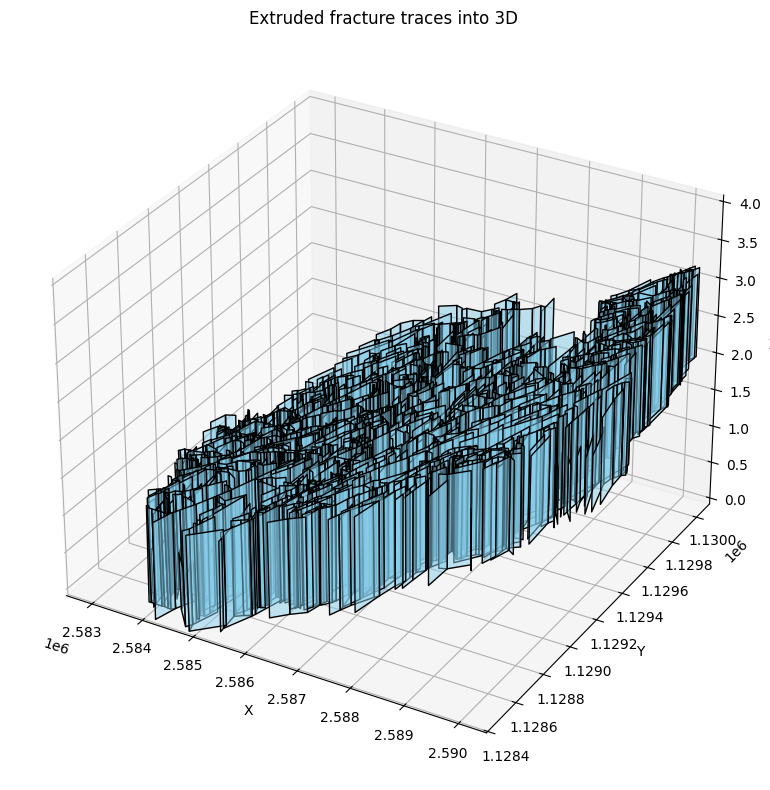

In [8]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

poly3d = Poly3DCollection(plane_faces, alpha=0.5, facecolors='skyblue', edgecolors='k')
ax.add_collection3d(poly3d)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Extruded fracture traces into 3D")
ax.auto_scale_xyz([2583000, 2590000], [1128500, 1130000], [0,4])
plt.tight_layout()
plt.show()

### Get dip direction and dip from planes

In [9]:
def face_dipdir(face):
    p1, p2, p3 = np.array(face[0]), np.array(face[1]), np.array(face[2])
    v1 = p2 - p1
    v2 = p3 - p1
    normal = np.cross(v1, v2)
    normal = normal / np.linalg.norm(normal)

    if normal[2] < 0:
        normal = -normal

    dip = 90 - np.degrees(np.arccos(abs(normal[2])))

    strike = (np.degrees(np.arctan2(normal[1], normal[0])) + 360) % 360
    dip_direction = (strike - 90) % 360 #Checar como fazer o dip direction direito
    
    return round(dip,0), round(dip_direction,0), round(strike,0)

In [10]:
dip_dipdir=[face_dipdir(face) for face in plane_faces]

## Exporting

In [11]:
import pandas as pd

In [12]:
data = []
for plane_idx, plane in enumerate(plane_faces):
    for point_idx, point in enumerate(plane):
        data.append({
            'plane': plane_idx + 1,
            'point': point_idx + 1,
            'x': point[0],
            'y': point[1],
            'z': point[2]
        })

df = pd.DataFrame(data)
df.to_csv('tsan3d.csv', index=False)

In [13]:
# Create DataFrame
df = pd.DataFrame(dip_dipdir, columns=['dip', 'dip_dir', 'azimuth'])

# Export to CSV
df.to_csv('tsan_3d_dipdir.csv', index=False)

## Create a 3D Graph
- nodes at plane centers and corners # - edges from center to corne and es between centers where planes intersect

In [14]:
from scipy.spatial import distance

In [15]:
# Read the CSV
df = pd.read_csv('tsan3d.csv')

In [16]:
df

,plane,point,x,y,z
0,1,1,2.583485e+06,1.128945e+06,0.000000
1,1,2,2.583533e+06,1.128879e+06,0.000000
2,1,3,2.583529e+06,1.128876e+06,1.209609
3,1,4,2.583481e+06,1.128943e+06,1.209609
4,2,1,2.583533e+06,1.128879e+06,0.000000
...,...,...,...,...,...
11651,2913,4,2.587772e+06,1.129308e+06,1.294095
11652,2914,1,2.587737e+06,1.129278e+06,0.000000
11653,2914,2,2.587683e+06,1.129269e+06,0.000000
11654,2914,3,2.587683e+06,1.129273e+06,1.294095


In [17]:
# Group by plane
planes = []
for plane_id, group in df.groupby('plane'):
    points = group[['x', 'y', 'z']].values
    planes.append({'id': plane_id, 'points': points})

In [18]:
# Create graph
G = nx.Graph()

In [19]:
# Add center nodes for each plane
plane_centers = {}
for plane in planes:
    center = np.mean(plane['points'], axis=0)
    node_name = f'plane_{plane["id"]}'
    G.add_node(node_name, pos=center, type='center')
    plane_centers[plane['id']] = center
    # Optionally, add nodes for each corner
    for i, pt in enumerate(plane['points']):
        corner_name = f'plane_{plane["id"]}_corner_{i+1}'
        G.add_node(corner_name, pos=pt, type='corner')
        G.add_edge(node_name, corner_name)

In [20]:
# Add edges between plane centers if planes intersect (share a corner)
for i, plane1 in enumerate(planes):
    for j, plane2 in enumerate(planes):
        if i >= j:
            continue
        # Check if any corners are close (intersection)
        for pt1 in plane1['points']:
            for pt2 in plane2['points']:
                if np.linalg.norm(pt1 - pt2) < 1e-5:  # adjust tolerance as needed
                    G.add_edge(f'plane_{plane1["id"]}', f'plane_{plane2["id"]}')
                    break

In [21]:
print(G)

Graph with 14570 nodes and 16111 edges


C:\Users\burgoaa\AppData\Local\Temp\ipykernel_8840\3824010274.py:28: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\burgoaa\Anaconda3\envs\geo_env\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


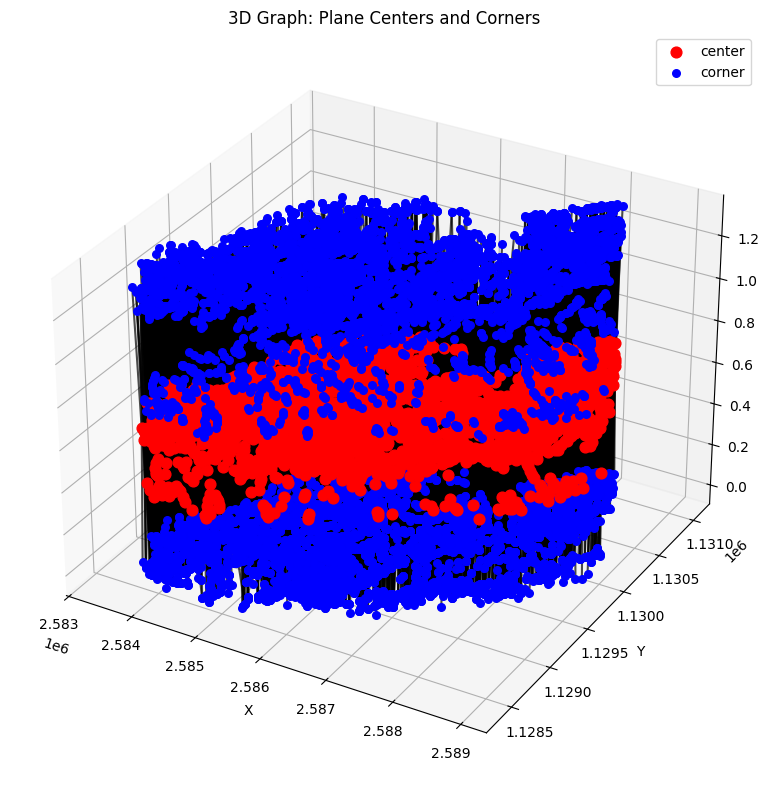

In [22]:
# 3D Plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Draw edges
for u, v in G.edges():
    x = [G.nodes[u]['pos'][0], G.nodes[v]['pos'][0]]
    y = [G.nodes[u]['pos'][1], G.nodes[v]['pos'][1]]
    z = [G.nodes[u]['pos'][2], G.nodes[v]['pos'][2]]
    ax.plot(x, y, z, color='k', alpha=0.7)

# Draw nodes (plane centers in red, corners in blue)
for n, d in G.nodes(data=True):
    x, y, z = d['pos']
    if d['type'] == 'center':
        ax.scatter(x, y, z, color='red', s=60, label='center' if 'center' not in ax.get_legend_handles_labels()[1] else "")
    else:
        ax.scatter(x, y, z, color='blue', s=30, label='corner' if 'corner' not in ax.get_legend_handles_labels()[1] else "")

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('3D Graph: Plane Centers and Corners')
# Only show unique labels in legend
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
ax.legend(unique.values(), unique.keys())
plt.tight_layout()
plt.show()

In [31]:
S = [G.subgraph(c).copy() for c in nx.connected_components(G)]

In [33]:
Scc = [len(c) for c in sorted(nx.connected_components(G), key=len, reverse=True)]

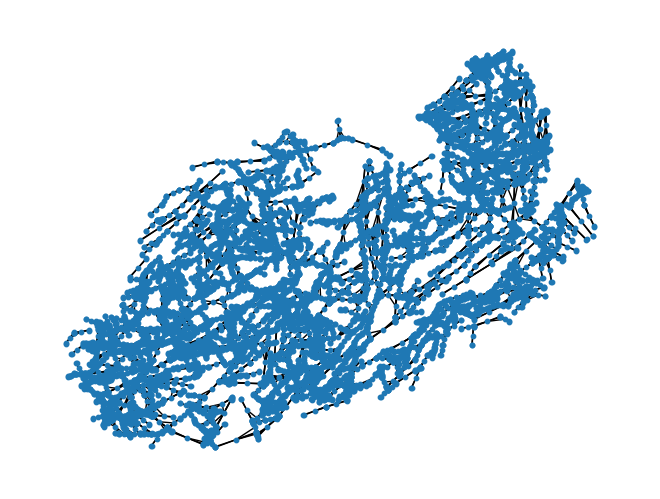

In [22]:
# 2D Plot:
pos = {n: G.nodes[n]['pos'][:2] for n in G.nodes}
nx.draw(G, pos, with_labels=False, node_size=10)
plt.show()

C:\Users\burgoaa\AppData\Local\Temp\ipykernel_536\3820471951.py:13: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


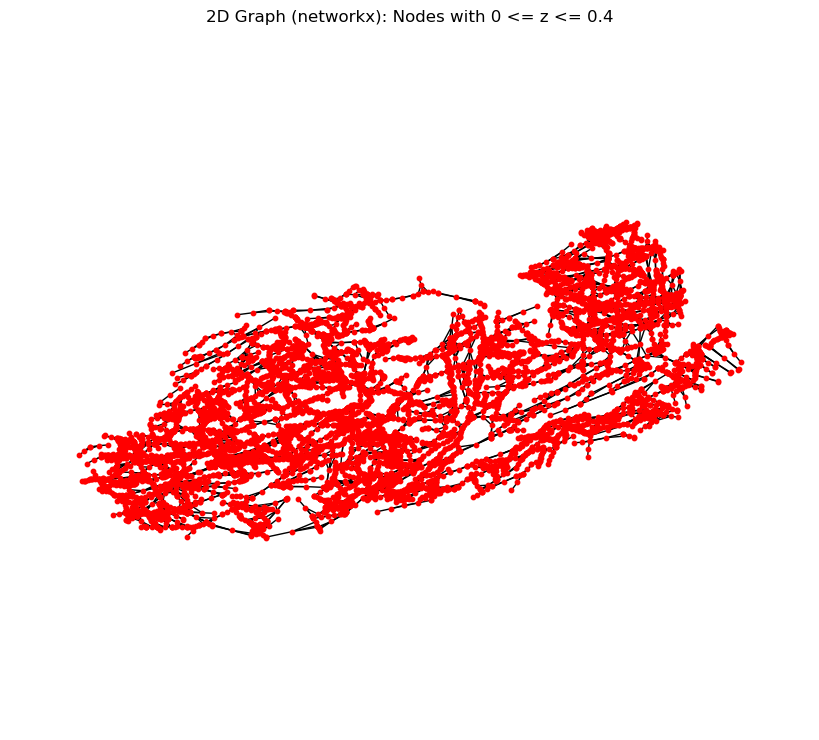

In [61]:
# 2D plot using networkx draw, filtering nodes with 0 <= z <= 0.4
zmin, zmax = 0, 1
pos = nx.get_node_attributes(G, 'pos')
nodes_2d = [n for n, p in pos.items() if zmin <= p[2] <= zmax]
pos_2d = {n: (p[0], p[1]) for n, p in pos.items() if n in nodes_2d}

plt.figure(figsize=(8, 7))
nx.draw(G.subgraph(nodes_2d), pos=pos_2d, with_labels=False, node_size=10, node_color='red', edge_color='k')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('2D Graph (networkx): Nodes with 0 <= z <= 0.4')
plt.axis('equal')
plt.tight_layout()
plt.show()

In [40]:
# Build a 3D graph with nodes only at edge intersections and ends
from itertools import combinations

def point_tuple(pt, tol=1e-5):
    # Helper to round and tuple a point for hashing
    return tuple(np.round(pt, 5))

# 1. Find all unique intersection points (shared corners) and all unique edge ends
all_points = []
for plane in planes:
    for pt in plane['points']:
        all_points.append(point_tuple(pt))

from collections import Counter
point_counts = Counter(all_points)

# Intersection points: appear in more than one plane
intersection_points = {pt for pt, count in point_counts.items() if count > 1}
# End points: appear only once
end_points = {pt for pt, count in point_counts.items() if count == 1}

In [41]:
# 2. Build a new graph with only these nodes
G3 = nx.Graph()

# Add nodes for all intersection and end points
for pt in intersection_points.union(end_points):
    G3.add_node(pt, pos=np.array(pt), type='intersection' if pt in intersection_points else 'end')

In [59]:
print(G3)

Graph with 8611 nodes and 11654 edges


In [42]:
# 3. For each plane, add edges between consecutive corners if both are in our node set
for plane in planes:
    pts = [point_tuple(pt) for pt in plane['points']]
    n = len(pts)
    for i in range(n):
        pt1 = pts[i]
        pt2 = pts[(i+1)%n]  # wrap around for closed polygon
        if pt1 in G3.nodes and pt2 in G3.nodes:
            G3.add_edge(pt1, pt2, plane=plane['id'])

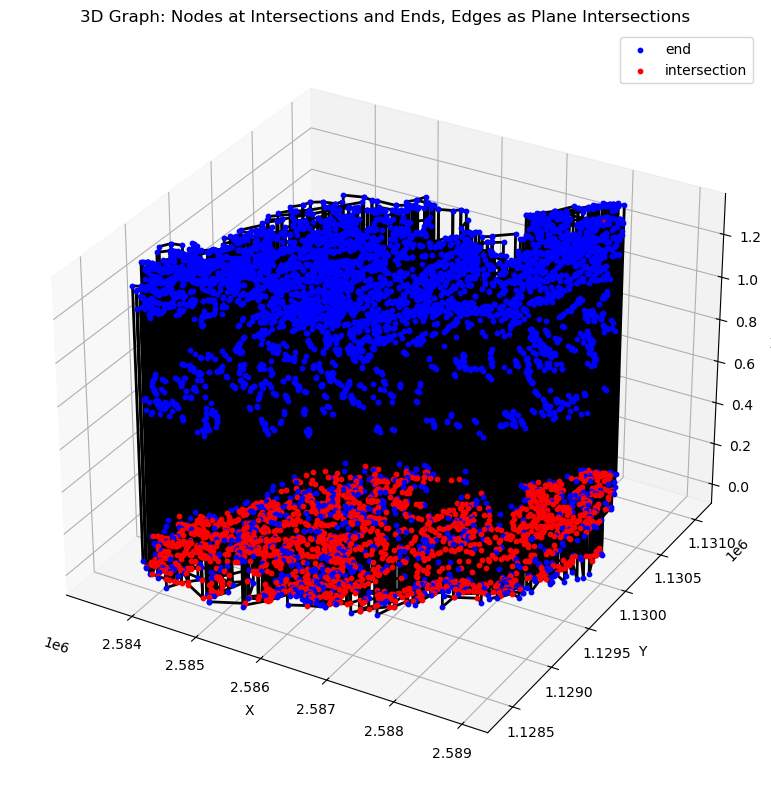

In [44]:
# 4. 3D Plot: nodes at intersections and ends, edges as intersection lines
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Draw edges
for u, v in G3.edges():
    x = [u[0], v[0]]
    y = [u[1], v[1]]
    z = [u[2], v[2]]
    ax.plot(x, y, z, color='k', lw=2)

# Draw nodes
for pt, data in G3.nodes(data=True):
    color = 'red' if data['type'] == 'intersection' else 'blue'
    ax.scatter(pt[0], pt[1], pt[2], color=color, s=10, label=data['type'])

# Remove duplicate labels
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys())

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('3D Graph: Nodes at Intersections and Ends, Edges as Plane Intersections')
plt.tight_layout()
plt.show()

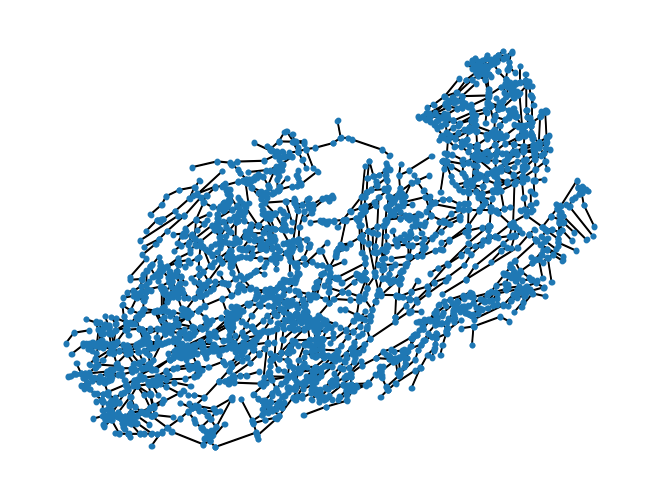

In [46]:
# 2D Plot:
pos = {n: G3.nodes[n]['pos'][:2] for n in G3.nodes}
nx.draw(G3, pos, with_labels=False, node_size=10)
plt.show()

C:\Users\burgoaa\AppData\Local\Temp\ipykernel_536\3097674277.py:13: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


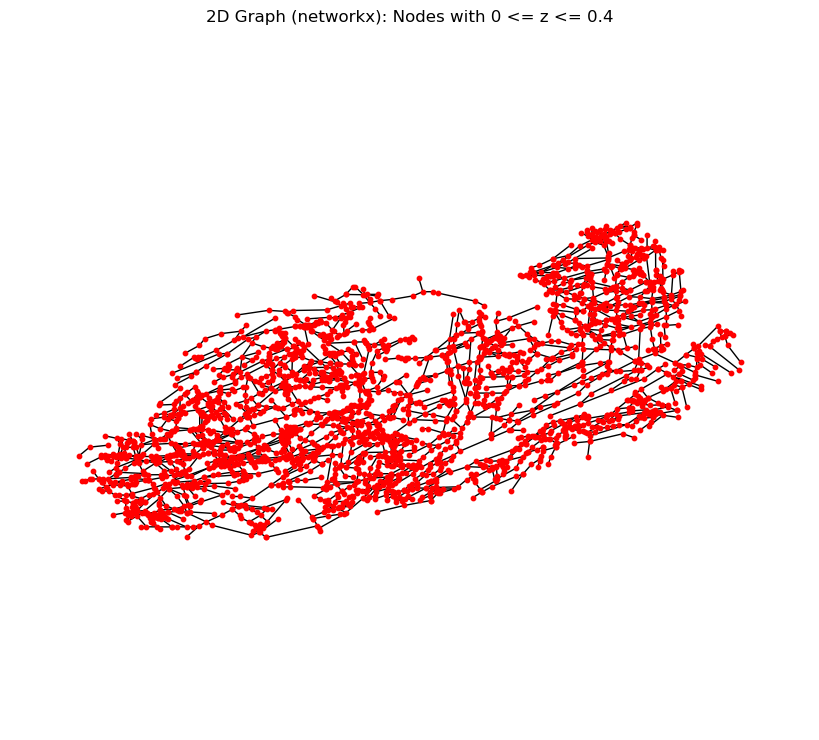

In [58]:
# 2D plot using networkx draw, filtering nodes with 0 <= z <= 0.4
zmin, zmax = 0, 0.4
pos = nx.get_node_attributes(G3, 'pos')
nodes_2d = [n for n, p in pos.items() if zmin <= p[2] <= zmax]
pos_2d = {n: (p[0], p[1]) for n, p in pos.items() if n in nodes_2d}

plt.figure(figsize=(8, 7))
nx.draw(G3.subgraph(nodes_2d), pos=pos_2d, with_labels=False, node_size=10, node_color='red', edge_color='k')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('2D Graph (networkx): Nodes with 0 <= z <= 0.4')
plt.axis('equal')
plt.tight_layout()
plt.show()

In [51]:
print(G3)

Graph with 8611 nodes and 11654 edges


In [6]:
#Export adjacency List
nx.write_edgelist(G, f'data/output/{name}_edgelist')

#Export edges as list
with open(f'data/output/G3_edgelist', 'r') as infile, open(f'data/output/G3_edge.dat', 'w') as outfile:
    for line in infile:
        parts = line.split()
        new_line = f"{int(parts[0]) + 1} {int(parts[1]) + 1}\n"
    
        outfile.write(new_line)

NameError: name 'nx' is not defined

In [ ]:
#Export nodes coordinates as a list
positions = nx.get_node_attributes(G, 'pos')
coordinates_list = list(positions.values())

with open(f'data/output/{name}_nodes.dat', 'w') as outfile:
    for coordinate in coordinates_list:
        outfile.write(f"{coordinate[0]} {coordinate[1]} {0}\n")